In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
np.random.seed(42)
n = 100
study_hours = np.random.randint(1, 9, n)
attendance = np.random.randint(50, 101, n)
assignments = np.random.randint(40, 101, n)
previous_score = np.random.randint(35, 96, n)
maths = np.random.randint(40, 101, n)
science = np.random.randint(40, 101, n)
english = np.random.randint(40, 101, n)
final_marks = (
    0.20 * study_hours * 10 +
    0.20 * attendance +
    0.20 * assignments +
    0.40 * previous_score +
    np.random.normal(0, 5, n)
)
final_marks = np.clip(final_marks, 0, 100).round(2)
df = pd.DataFrame({
    "Student_ID": range(1, n + 1),
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Assignments": assignments,
    "Previous_Score": previous_score,
    "Maths": maths,
    "Science": science,
    "English": english,
    "Final_Marks": final_marks
})
print(df.head())

   Student_ID  Study_Hours  Attendance  Assignments  Previous_Score  Maths  \
0           1            7          67           98              43     46   
1           2            4          75           90              94     42   
2           3            5          93           61              93     56   
3           4            7          83           67              40     72   
4           5            3          59           41              50     87   

   Science  English  Final_Marks  
0       52       94        65.99  
1       99       42        75.14  
2       97       51        82.50  
3       46       65        61.54  
4       96       55        50.06  


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst Five Records:")
print(df.head())

Dataset Shape: (100, 9)

Column Names:
['Student_ID', 'Study_Hours', 'Attendance', 'Assignments', 'Previous_Score', 'Maths', 'Science', 'English', 'Final_Marks']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student_ID      100 non-null    int64  
 1   Study_Hours     100 non-null    int32  
 2   Attendance      100 non-null    int32  
 3   Assignments     100 non-null    int32  
 4   Previous_Score  100 non-null    int32  
 5   Maths           100 non-null    int32  
 6   Science         100 non-null    int32  
 7   English         100 non-null    int32  
 8   Final_Marks     100 non-null    float64
dtypes: float64(1), int32(7), int64(1)
memory usage: 4.4 KB

First Five Records:
   Student_ID  Study_Hours  Attendance  Assignments  Previous_Score  Maths  \
0           1            7          67           98              43   

In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Student_ID        0
Study_Hours       0
Attendance        0
Assignments       0
Previous_Score    0
Maths             0
Science           0
English           0
Final_Marks       0
dtype: int64


In [5]:
df["Attendance"] = df["Attendance"].fillna(df["Attendance"].median())
df["Study_Hours"] = df["Study_Hours"].fillna(df["Study_Hours"].median())
df["Assignments"] = df["Assignments"].fillna(df["Assignments"].median())

print("Missing values handled successfully!")
print(df.isnull().sum())

Missing values handled successfully!
Student_ID        0
Study_Hours       0
Attendance        0
Assignments       0
Previous_Score    0
Maths             0
Science           0
English           0
Final_Marks       0
dtype: int64


In [6]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset after removing duplicates:")
print(df.shape)

Duplicate Records: 0
Dataset after removing duplicates:
(100, 9)


In [7]:
df["Average_Subject_Marks"] = df[["Maths", "Science", "English"]].mean(axis=1)

df["Performance"] = np.where(
    df["Final_Marks"] >= 85, "Excellent",
    np.where(df["Final_Marks"] >= 70, "Good",
    np.where(df["Final_Marks"] >= 50, "Average", "Needs Improvement"))
)

print(df[["Student_ID", "Average_Subject_Marks", "Final_Marks", "Performance"]].head())

   Student_ID  Average_Subject_Marks  Final_Marks Performance
0           1              64.000000        65.99     Average
1           2              61.000000        75.14        Good
2           3              68.000000        82.50        Good
3           4              61.000000        61.54     Average
4           5              79.333333        50.06     Average


In [8]:
print("Descriptive Statistics:")
print(df.describe())

Descriptive Statistics:
       Student_ID  Study_Hours  Attendance  Assignments  Previous_Score  \
count  100.000000   100.000000   100.00000   100.000000      100.000000   
mean    50.500000     4.600000    75.09000    71.400000       65.020000   
std     29.011492     2.146173    14.19994    18.428678       17.756478   
min      1.000000     1.000000    50.00000    40.000000       35.000000   
25%     25.750000     3.000000    63.00000    56.000000       52.000000   
50%     50.500000     4.000000    75.00000    72.000000       66.000000   
75%     75.250000     6.000000    86.50000    88.000000       82.000000   
max    100.000000     8.000000   100.00000    98.000000       95.000000   

           Maths     Science   English  Final_Marks  Average_Subject_Marks  
count  100.00000  100.000000  100.0000    100.00000             100.000000  
mean    72.94000   72.910000   69.2100     65.08230              71.686667  
std     15.83872   18.652644   17.2488      9.59451              10.1

In [9]:
print("Average Attendance:", round(df["Attendance"].mean(), 2))
print("Highest Attendance:", df["Attendance"].max())
print("Lowest Attendance:", df["Attendance"].min())

low_attendance = df[df["Attendance"] < 75]

print("\nStudents with Attendance Below 75%:")
print(low_attendance[["Student_ID", "Attendance", "Final_Marks"]])

Average Attendance: 75.09
Highest Attendance: 100
Lowest Attendance: 50

Students with Attendance Below 75%:
    Student_ID  Attendance  Final_Marks
0            1          67        65.99
4            5          59        50.06
6            7          63        50.06
9           10          64        66.05
10          11          57        58.70
11          12          63        61.79
12          13          72        67.39
14          15          70        65.74
15          16          65        57.39
17          18          67        70.69
19          20          73        68.07
21          22          74        70.11
25          26          64        51.35
27          28          50        59.98
28          29          74        73.51
29          30          56        69.26
30          31          58        58.57
31          32          73        48.93
32          33          50        58.79
34          35          57        70.12
35          36          73        64.94
36         

Subject-Wise Average Marks:
Maths      72.94
Science    72.91
English    69.21
dtype: float64


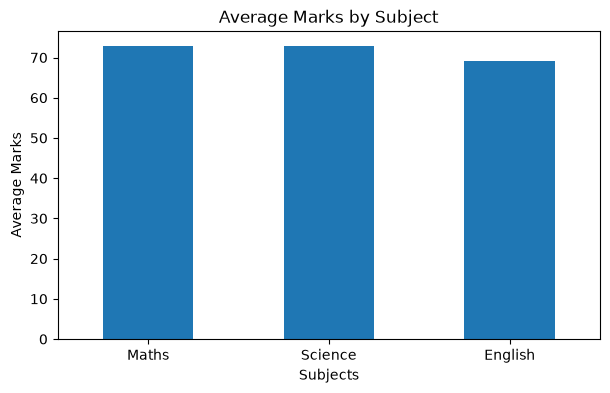

In [10]:
subject_average = df[["Maths", "Science", "English"]].mean()

print("Subject-Wise Average Marks:")
print(subject_average)

subject_average.plot(kind="bar", figsize=(7, 4))
plt.title("Average Marks by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.show()

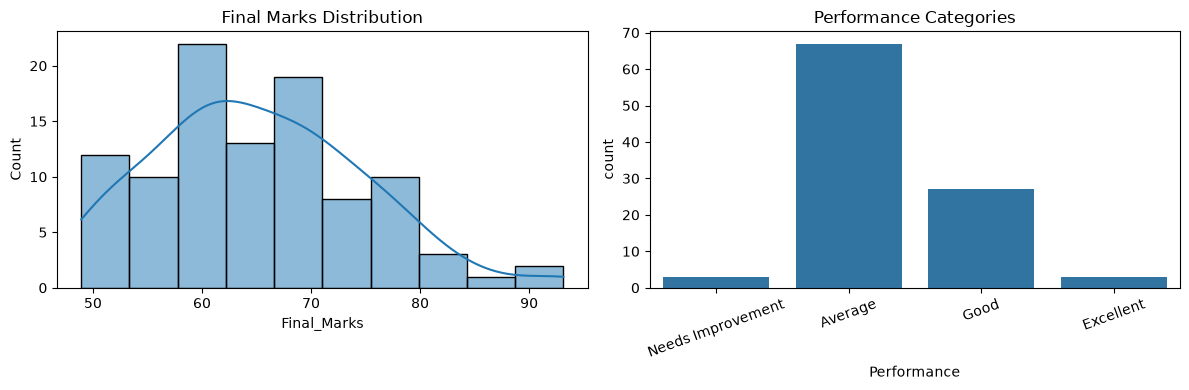

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(data=df, x="Final_Marks", bins=10, kde=True)
plt.title("Final Marks Distribution")

plt.subplot(1, 2, 2)
sns.countplot(data=df, x="Performance",
              order=["Needs Improvement", "Average", "Good", "Excellent"])
plt.title("Performance Categories")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

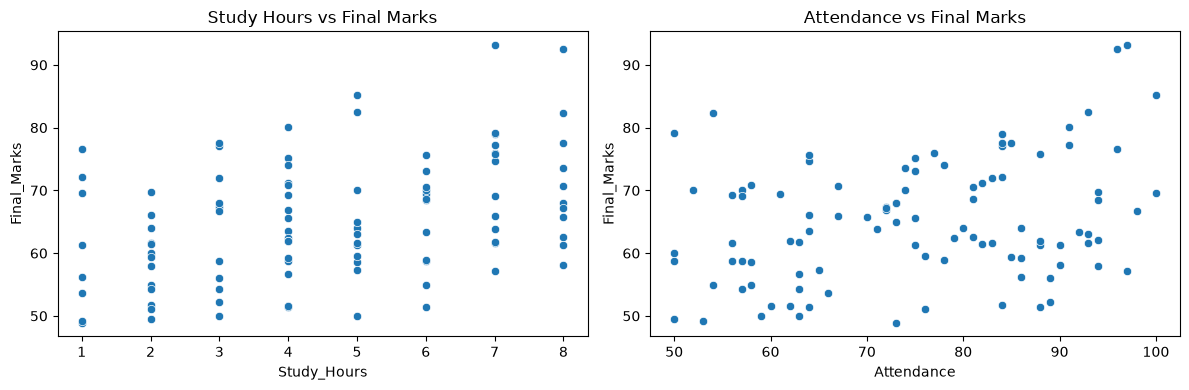

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x="Study_Hours", y="Final_Marks")
plt.title("Study Hours vs Final Marks")

plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x="Attendance", y="Final_Marks")
plt.title("Attendance vs Final Marks")

plt.tight_layout()
plt.show()

Correlation Matrix:
                       Student_ID  Study_Hours  Attendance  Assignments  \
Student_ID               1.000000    -0.120537    0.041940    -0.110429   
Study_Hours             -0.120537     1.000000   -0.026317     0.012003   
Attendance               0.041940    -0.026317    1.000000    -0.126090   
Assignments             -0.110429     0.012003   -0.126090     1.000000   
Previous_Score           0.013667    -0.117474    0.120056    -0.076393   
Maths                    0.012024    -0.088076   -0.030875    -0.158378   
Science                  0.038424    -0.184601   -0.017321     0.019706   
English                 -0.023001    -0.006985    0.216721     0.098146   
Final_Marks             -0.100217     0.399568    0.304583     0.288056   
Average_Subject_Marks    0.016828    -0.163489    0.096471    -0.014771   

                       Previous_Score     Maths   Science   English  \
Student_ID                   0.013667  0.012024  0.038424 -0.023001   
Study_Hours 

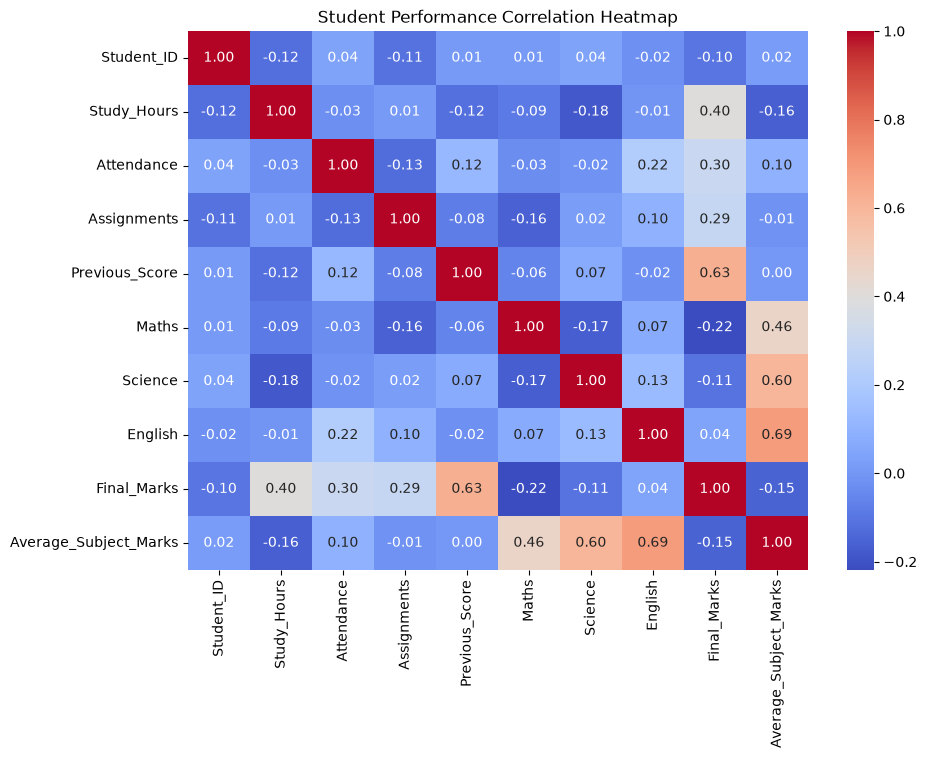

In [13]:
correlation_matrix = df.select_dtypes(include="number").corr()

print("Correlation Matrix:")
print(correlation_matrix)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Student Performance Correlation Heatmap")
plt.show()

In [15]:
features = ["Study_Hours", "Attendance", "Assignments", "Previous_Score"]

X = df[features]
y = df["Final_Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 2))

Model Evaluation Results
MAE: 3.57
MSE: 19.46
RMSE: 4.41
R-squared: 0.84


In [16]:
df.to_csv("student_performance_final.csv", index=False)

report = f"""
STUDENT PERFORMANCE & LEARNING ANALYTICS

Total Students: {len(df)}
Average Final Marks: {df["Final_Marks"].mean():.2f}
Average Attendance: {df["Attendance"].mean():.2f}%

Subject-Wise Average Marks:
{subject_average.to_string()}

Model Evaluation:
MAE: {mae:.2f}
MSE: {mse:.2f}
RMSE: {rmse:.2f}
R-Squared: {r2:.2f}

Dataset Type: Synthetic Sample Data
"""

with open("student_performance_final_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("Project completed successfully!")
print("Final dataset and report saved successfully!")

Project completed successfully!
Final dataset and report saved successfully!
